In [ ]:
from tensorflow . keras . datasets import imdb
from tensorflow . keras . preprocessing . sequence import pad_sequences
from sklearn . model_selection import train_test_split
num_words = 10000 # keep the 10k most frequent words
maxlen = 200 # fix every review to 200 tokens
( X_train , y_train ) , ( X_test , y_test ) = imdb . load_data ( num_words = num_words )

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [9]:
X_train = pad_sequences ( X_train , maxlen = maxlen ) # -> (25000 , 200)
X_test = pad_sequences ( X_test , maxlen = maxlen )
X_train , X_val , y_train , y_val = train_test_split (
X_train , y_train , test_size =0.2 , random_state =42)

In [10]:
model = Sequential([
    Embedding(input_dim=num_words, output_dim=128, input_length=maxlen),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.5),
    Dense(1, activation="sigmoid"),
])

# Build and display the parameter breakdown (1,378,945 total parameters)
model.build(input_shape=(None, maxlen))
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,378,945 (5.26 MB)

 Trainable params: 1,378,945 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
)

loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {accuracy * 100:.2f}%")

Epoch 1/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 125s 471ms/step - accuracy: 0.7646 - loss: 0.4785 - val_accuracy: 0.8422 - val_loss: 0.3611
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 148s 497ms/step - accuracy: 0.8943 - loss: 0.2718 - val_accuracy: 0.8508 - val_loss: 0.3405
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 132s 457ms/step - accuracy: 0.9315 - loss: 0.1881 - val_accuracy: 0.8695 - val_loss: 0.3558
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 116s 463ms/step - accuracy: 0.9535 - loss: 0.1351 - val_accuracy: 0.8670 - val_loss: 0.3891
Epoch 5/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 137s 443ms/step - accuracy: 0.9618 - loss: 0.1118 - val_accuracy: 0.8665 - val_loss: 0.4001
Test accuracy: 85.13%


In [17]:
import re

# Cache the word index once outside the function for speed
word_index = imdb.get_word_index()


def predict_sentiment(review):
  # Clean punctuation and lowercase to match IMDB vocabulary
  words = re.sub(r"[^\w\s]", "", review.lower()).split()

  # Map words to indices (+3 offset for <PAD>, <START>, <UNK>)
  enc = []
  for w in words:
    idx = word_index.get(w, 0) + 3
    enc.append(idx if idx < num_words else 2)  # Map out-of-vocab words to <UNK> (2)

  padded = pad_sequences([enc], maxlen=maxlen)
  p = model.predict(padded, verbose=0)[0][0]
  label = "Positive" if p >= 0.5 else "Negative"
  return f"{label} (score: {p:.4f})"


# Test on custom reviews
print(predict_sentiment("A brilliant, moving film with incredible acting."))
print(predict_sentiment("The plot was terrible and a complete waste of time."))

Negative (score: 0.4953)
Negative (score: 0.4914)


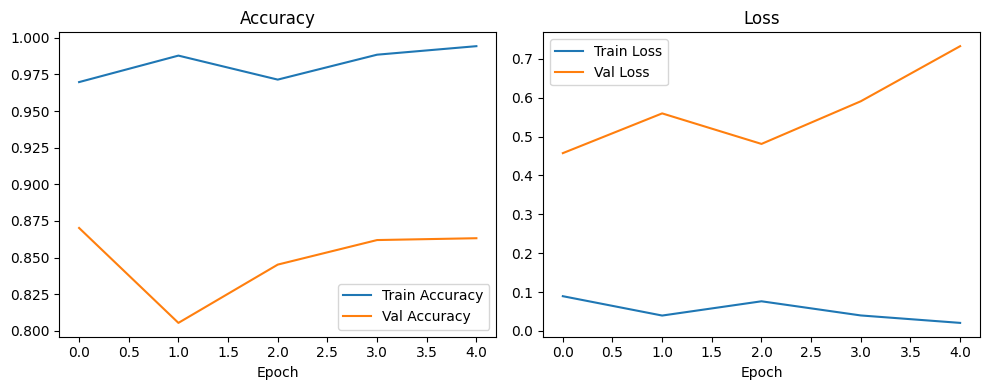

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

# Lab 7 ·Example A — IMDB Sentiment with a Bidirectional LSTM



In [19]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.layers import Bidirectional, Dense, Dropout, Embedding, Input, LSTM
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [20]:
# Q1a) hyperparameters
num_words = 10000  # TODO (Q1a): keep the 10000 most frequent words
maxlen = 200  # TODO (Q1a): fix every review to 200 tokens

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=num_words)

# Q1b) pad both sets to a fixed length
X_train = pad_sequences(X_train, maxlen=maxlen)  # TODO (Q1b): maxlen
X_test = pad_sequences(X_test, maxlen=maxlen)  # TODO (Q1b): maxlen

# Q1c) hold out 20% of training data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)  # TODO (Q1c): 0.2

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)

# Quick check (given)
assert X_train.shape[1] == 200, "reviews should be padded to length 200"
assert set(np.unique(y_train)) <= {0, 1}, "labels should be binary (0/1)"
print(
    "Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000,"
    " 200)"
)

X_train: (20000, 200)  X_val: (5000, 200)  X_test: (25000, 200)
Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000, 200)


In [21]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding: vocabulary size -> 128-dim word vectors
model.add(
    Embedding(input_dim=num_words, output_dim=128)
)  # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM with 64 units, returning ONE summary vector
model.add(
    Bidirectional(LSTM(64, return_sequences=False))
)  # TODO (Q2b): 64, False

# Q2c) Dropout to reduce overfitting
model.add(Dropout(0.5))  # TODO (Q2c): 0.5

# Q2d) Output: one neuron, sigmoid (positive/negative probability)
model.add(Dense(1, activation="sigmoid"))  # TODO (Q2d): 1, 'sigmoid'

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,378,945 (5.26 MB)

 Trainable params: 1,378,945 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# Q3a) compile for binary classification
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",  # TODO (Q3a): 'binary_crossentropy'
    metrics=["accuracy"],
)

# Q3b) train
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=5,  # TODO (Q3b): 5
    batch_size=64,
)  # TODO (Q3b): 64

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 145s 451ms/step - accuracy: 0.7772 - loss: 0.4576 - val_accuracy: 0.8514 - val_loss: 0.3506
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 143s 453ms/step - accuracy: 0.8972 - loss: 0.2660 - val_accuracy: 0.8696 - val_loss: 0.3055
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 451ms/step - accuracy: 0.9270 - loss: 0.1964 - val_accuracy: 0.8330 - val_loss: 0.3691
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 455ms/step - accuracy: 0.9470 - loss: 0.1505 - val_accuracy: 0.8672 - val_loss: 0.3510
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 208s 476ms/step - accuracy: 0.9597 - loss: 0.1124 - val_accuracy: 0.8622 - val_loss: 0.4127


782/782 ━━━━━━━━━━━━━━━━━━━━ 45s 57ms/step - accuracy: 0.8539 - loss: 0.4364
Test accuracy: 85.39%


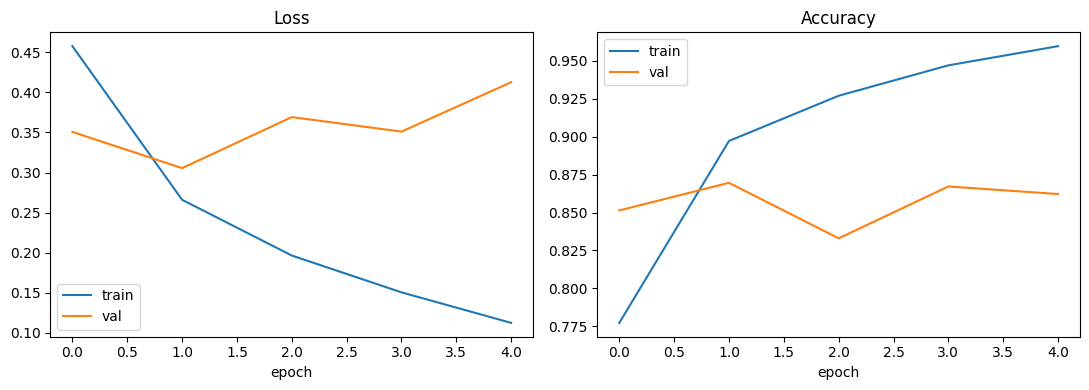

In [24]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")  # expect ~ 86-88%

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")  # TODO (Q4a): 'val_loss'
plt.title("Loss")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(
    history.history["val_accuracy"], label="val"
)  # TODO (Q4b): 'val_accuracy'
plt.title("Accuracy")
plt.xlabel("epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
word_index = imdb.get_word_index()


def predict_sentiment(review):
  enc = [word_index.get(w, 0) + 3 for w in review.lower().split()]
  padded = pad_sequences([enc], maxlen=maxlen)
  p = model.predict(padded, verbose=0)[0][0]
  # Q5) threshold the sigmoid at 0.5
  return "Positive" if p >= 0.5 else "Negative"  # TODO (Q5): 0.5


for r in [
    "this film was absolutely wonderful and moving",
    "a boring dull waste of time",
]:
  print(f"{predict_sentiment(r):8s} <- {r}")

Positive <- this film was absolutely wonderful and moving
Negative <- a boring dull waste of time


 answers:

1. Why pad:
Neural networks require fixed-shape rectangular tensors (`(batch_size, 200)`) to process batches efficiently, so padding and truncating make all reviews uniform in length.
2. Embedding vs. One-Hot: One-hot vectors are huge (`10,000`-d) and treat all words as unrelated, whereas Embeddings learn compact (`128`-d) vectors that group similar words together.
3. Why `return_sequences=False`:
Sentiment classification needs only one final summary vector (`128`-d) for the whole review, not an output at every word step.
4. Why `sigmoid` + `binary_crossentropy`:
There are only two classes (`0` or `1`), so a single `sigmoid` probability with `binary_crossentropy` fits binary classification (`softmax` is for 3+ classes).
5. Validation loss & Dropout:
Rising validation loss indicates overfitting (memorizing training data); `Dropout(0.5)` randomly disables half the features during training so the model generalizes better.


# Lab 7 Example B — Reuters Topic Classification with a Bidirectional LSTM


In [26]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import reuters
from tensorflow.keras.layers import Bidirectional, Dense, Dropout, Embedding, Input, LSTM
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [27]:
num_words = 10000  # TODO (Q1a): 10000
maxlen = 200  # TODO (Q1a): 200

(X_train, y_train), (X_test, y_test) = reuters.load_data(
    num_words=num_words, test_split=0.2
)

# Q1b) pad both sets
X_train = pad_sequences(X_train, maxlen=maxlen)  # TODO (Q1b): maxlen
X_test = pad_sequences(X_test, maxlen=maxlen)  # TODO (Q1b): maxlen

# Q1c) how many topic classes? (labels are integers 0..45)
num_classes = int(max(y_train)) + 1  # TODO (Q1c): int(max(y_train)) + 1
print("X_train:", X_train.shape, " classes:", num_classes)

# Quick check (given)
assert X_train.shape[1] == 200, "pad reviews to length 200"
assert num_classes == 46, "Reuters has 46 topic classes"
print("Task 1 looks correct ✔")

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (8982, 200)  classes: 46
Task 1 looks correct ✔


In [28]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding
model.add(
    Embedding(input_dim=num_words, output_dim=128)
)  # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM -> one summary vector
model.add(
    Bidirectional(LSTM(64, return_sequences=False))
)  # TODO (Q2b): 64, False

model.add(Dropout(0.5))

# Q2c) Output: one neuron PER CLASS with softmax
model.add(
    Dense(num_classes, activation="softmax")
)  # TODO (Q2c): num_classes, 'softmax'

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_6 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 46)             │         5,934 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,384,750 (5.28 MB)

 Trainable params: 1,384,750 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Q3a) compile for integer multi-class labels
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",  # TODO (Q3a): 'sparse_categorical_crossentropy'
    metrics=["accuracy"],
)

# Q3b) train with a validation split
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,  # TODO (Q3b): 0.2
    epochs=10,  # TODO (Q3b): 10
    batch_size=64,
)  # TODO (Q3b): 64

Epoch 1/10
 10/113 ━━━━━━━━━━━━━━━━━━━━ 50s 493ms/step - accuracy: 0.1819 - loss: 3.7353

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")  # expect ~ 65-72%

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")  # TODO (Q4a): 'val_loss'
plt.title("Loss")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(
    history.history["val_accuracy"], label="val"
)  # TODO (Q4b): 'val_accuracy'
plt.title("Accuracy")
plt.xlabel("epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
probs = model.predict(X_test[:5], verbose=0)  # shape (5, 46)

# Q5) pick the most likely topic for each review
pred_classes = np.argmax(probs, axis=1)  # TODO (Q5): np.argmax(probs, axis=1)

for i in range(5):
  print(f"true topic: {y_test[i]:2d}   predicted: {pred_classes[i]:2d}")

Task 6 — Short answers

1. Three differences:
 (1) Output units:`46` neurons instead of `1`;
 (2) Activation: `'softmax'` (producing a probability distribution summing to 1 across all 46 classes) instead of `'sigmoid'`;
  (3) Loss: `'sparse_categorical_crossentropy'` instead of `'binary_crossentropy'`.
2. Why `sparse_categorical_crossentropy`:
 The target labels `y_train` are stored as single integer indices (`0` through `45`) rather than 46-element one-hot encoded vectors. `sparse_categorical_crossentropy` computes categorical cross-entropy directly from integer labels without requiring manual one-hot encoding.
3. Reusing the sequence backbone:
 An `Embedding` + `Bidirectional LSTM` acts as a general-purpose text feature extractor that encodes any word sequence into a dense semantic summary vector. Because the representation step is task-agnostic, you can reuse the exact same backbone across different NLP tasks and simply swap the final `Dense` classification head.
4. Why 46-way accuracy is lower:
Choosing correctly among 46 classes is much harder than binary classification (random guessing drops from 50% to ~2.2%), topics often overlap in vocabulary (e.g., *crude oil* vs. *energy*), and Reuters has severe class imbalance with fewer training samples (~8,982 total) spread across many rare topics.
